# 04 · Análise espacial: bairros e logradouros

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/renanbrettas/Projeto-ci-ncia-de-dados---Podas-de-rvore/blob/main/04_analise_espacial.ipynb)

**Projeto:** Chamados de poda de árvore no Rio de Janeiro &nbsp;·&nbsp; **Parte 4 de 5**

---

### Contexto
Com o recorte e a extração definidos, os chamados são distribuídos no mapa da cidade, por bairro e por logradouro, depois de conferir as geometrias oficiais.

### Pergunta
> Onde se concentram os chamados de manejo arbóreo e quais vias lideram?

### Dados utilizados
- `adm_central_atendimento_1746.chamado`
- `dados_mestres.bairro`
- `dados_mestres.logradouro`
- `adm_cor_comando.ocorrencias`

### Roteiro
1. Polígonos de bairro e correção de geometrias inválidas
2. Eventos de árvore do COR × bairros (join espacial)
3. Manejo arbóreo por bairro (mapa)
4. Chamados por logradouro
5. Nomes e extensão dos logradouros
6. Mapa: bairros e os 10 logradouros com mais chamados

### Principais resultados
- 23 polígonos de bairro inválidos corrigidos com `make_valid`, sem variação de área.
- O bairro digitado no COR concorda com o polígono em **83,8%** dos eventos.
- **212.501** chamados de manejo arbóreo em 2021–2025, em 14.089 logradouros (mediana de 4 podas por logradouro).
- Lideram vias extensas (Estrada dos Bandeirantes, R. Conde de Bonfim, Av. Brasil): comparar exige **normalizar pela extensão**.

> ℹ️ As saídas deste notebook são as da execução original no Google Colab (dados extraídos do BigQuery
> em novembro de 2026), então os resultados podem ser lidos sem rodar nada. Para reproduzir, rode a
> célula de configuração abaixo (veja o [README](README.md)).

In [ ]:
# Configuração (rode primeiro)
import os
import subprocess
import sys
from pathlib import Path

# No Colab, informe o projeto do Google Cloud que vai pagar a leitura (veja o README):
# os.environ["GCP_PROJECT_ID"] = "seu-projeto-gcp"

RAIZ = Path.cwd()
if not (RAIZ / "src" / "podas").exists():  # aberto direto no Colab: baixa o código do repositório
    RAIZ = Path("/content/analise-podas")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/renanbrettas/Projeto-ci-ncia-de-dados---Podas-de-rvore.git", str(RAIZ)], check=True)
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
from google.cloud import bigquery

from podas.bq import get_client, rodar
from podas.config import ALVO, SENSIBILIDADE, ARQ_PODA, DATA_DIR, FIG_DIR, OUT_DIR

client = get_client()

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt

## 1. Polígonos de bairro (`dados_mestres.bairro`)

In [ ]:
import geopandas as gpd
import pandas as pd
from shapely import wkt

sql_bairro = """
SELECT id_bairro, nome, geometry_wkt
FROM `datario.dados_mestres.bairro`
"""
b = rodar(sql_bairro)
print(len(b), "bairros (esperado: 166)")

b["geometry"] = b["geometry_wkt"].apply(wkt.loads)
bairros = gpd.GeoDataFrame(b.drop(columns="geometry_wkt"), geometry="geometry", crs="EPSG:4326")
bairros["id_bairro"] = bairros["id_bairro"].astype(str).str.strip()

# Checagem: as coordenadas estão mesmo em lon/lat (hipótese)?
print(bairros.total_bounds)   # esperado ≈ [-43.8, -23.1, -43.1, -22.7]

custo estimado: 0.004 GB
167 bairros (esperado: 166)
[-43.79547479 -23.07634694 -43.10180176 -22.74880691]


In [ ]:
print(bairros["id_bairro"].duplicated().sum(), "id_bairro repetidos")
print(bairros["id_bairro"].isna().sum(), "id_bairro nulos")
print(bairros[bairros["id_bairro"].duplicated(keep=False)].sort_values("id_bairro")[["id_bairro", "nome"]])
print(bairros.geometry.is_valid.value_counts())

0 id_bairro repetidos
0 id_bairro nulos
Empty DataFrame
Columns: [id_bairro, nome]
Index: []
True     144
False     23
Name: count, dtype: int64


In [ ]:
from shapely.validation import make_valid

# Área antes (em CRS projetado, SIRGAS 2000 / UTM 23S, só para comparar)
area_antes = bairros.to_crs(31983).geometry.area

invalidos = ~bairros.geometry.is_valid
bairros.loc[invalidos, "geometry"] = bairros.loc[invalidos, "geometry"].apply(make_valid)

print(bairros.geometry.is_valid.value_counts())
print(bairros.geom_type.value_counts())

# Conferência: a reparação não deve mudar a área de forma relevante
area_depois = bairros.to_crs(31983).geometry.area
var = ((area_depois - area_antes) / area_antes).abs()
print("maior variação relativa de área:", round(float(var.max()), 4))
print(bairros.loc[var > 0.01, ["id_bairro", "nome"]])

True    167
Name: count, dtype: int64
Polygon         144
MultiPolygon     23
Name: count, dtype: int64


maior variação relativa de área: 0.0
Empty DataFrame
Columns: [id_bairro, nome]
Index: []


23 polígonos eram inválidos ("hole lies outside shell"). Eles foram corrigidos com `make_valid`,
**sem variação de área**, e viraram MultiPolygon.

## 2. Eventos de árvore do COR × bairros (join espacial)

In [ ]:
import geopandas as gpd
import pandas as pd
from shapely import wkt

# 1) polígonos de bairro (tabela pequena, custo desprezível)
bairros = rodar("""
SELECT id_bairro, nome, subprefeitura, geometry_wkt
FROM `datario.dados_mestres.bairro`
""")
gdf_bairros = gpd.GeoDataFrame(
    bairros.drop(columns="geometry_wkt"),
    geometry=bairros["geometry_wkt"].apply(wkt.loads),
    crs="EPSG:4326",
)
print(gdf_bairros.shape, gdf_bairros.is_valid.all())

# 2) eventos de árvore do COR com coordenada, 2021-2023
cor = rodar("""
SELECT id_pop, id_evento, data_inicio, bairro, latitude, longitude
FROM `datario.adm_cor_comando.ocorrencias`
WHERE id_pop IN ('11', '40')
  AND data_inicio >= TIMESTAMP '2021-01-01' AND data_inicio < TIMESTAMP '2024-01-01'
  AND latitude BETWEEN -23.08 AND -22.74
  AND longitude BETWEEN -43.80 AND -43.09
""")
gdf_cor = gpd.GeoDataFrame(
    cor,
    geometry=gpd.points_from_xy(cor["longitude"], cor["latitude"]),
    crs="EPSG:4326",
)

# 3) ponto dentro do polígono -> id_bairro
cor_bairro = gpd.sjoin(
    gdf_cor, gdf_bairros[["id_bairro", "nome", "geometry"]],
    how="left", predicate="within",
)
print("eventos sem bairro encontrado:", cor_bairro["id_bairro"].isna().sum())
print(cor_bairro.groupby("nome").size().sort_values(ascending=False).head(15))

custo estimado: 0.004 GB
(167, 4) False
custo estimado: 0.004 GB
eventos sem bairro encontrado: 33
nome
Alto da Boa Vista          77
Botafogo                   53
Tijuca                     52
Copacabana                 44
Grajaú                     42
Barra da Tijuca            40
Vila Isabel                39
Lagoa                      37
Laranjeiras                32
São Conrado                32
Itanhangá                  29
Centro                     24
Taquara                    23
Freguesia (Jacarepaguá)    21
Campo Grande               20
dtype: int64


In [ ]:
import unicodedata, re
from shapely.validation import explain_validity

# --- 1) diagnóstico dos polígonos ---
inv = gdf_bairros[~gdf_bairros.is_valid]
print("polígonos inválidos:", len(inv))
print(pd.DataFrame({"id_bairro": inv["id_bairro"], "nome": inv["nome"],
                    "motivo": inv.geometry.apply(explain_validity)}).to_string())
print("id_bairro duplicado:", gdf_bairros["id_bairro"].duplicated().sum(),
      "| nome duplicado:", gdf_bairros["nome"].duplicated().sum())

# --- 2) corrige e refaz o join ---
gdf_bairros["geometry"] = gdf_bairros.geometry.make_valid()
print("todos válidos agora:", gdf_bairros.is_valid.all())

cor_bairro = gpd.sjoin(
    gdf_cor, gdf_bairros[["id_bairro", "nome", "geometry"]],
    how="left", predicate="within",
)
print("\neventos no COR:", len(gdf_cor),
      "| linhas após join:", len(cor_bairro),
      "| índices repetidos (ponto em 2 polígonos):", cor_bairro.index.duplicated().sum())
print("sem bairro:", cor_bairro["id_bairro"].isna().sum())

# --- 3) distância dos sem bairro ao polígono mais próximo (CRS métrico) ---
M = "EPSG:31983"
sem = cor_bairro[cor_bairro["id_bairro"].isna()].drop(
    columns=["index_right", "id_bairro", "nome"], errors="ignore")
if len(sem):
    prox = gpd.sjoin_nearest(
        sem.to_crs(M),
        gdf_bairros[["id_bairro", "nome", "geometry"]].to_crs(M),
        how="left", distance_col="dist_m",
    )
    print("\n=== SEM BAIRRO: bairro em texto vs. mais próximo e distância ===")
    print(prox[["id_evento", "bairro", "nome", "dist_m"]]
          .sort_values("dist_m").round(0).to_string())

# --- 4) texto do COR vs. bairro por localização ---
def norm(s):
    if s is None or (isinstance(s, float) and pd.isna(s)):
        return None
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return " ".join(re.sub(r"[^a-z0-9 ]", " ", s).split())

cor_bairro = cor_bairro[~cor_bairro.index.duplicated(keep="first")].copy()
cor_bairro["bairro_txt"] = cor_bairro["bairro"].map(norm)
cor_bairro["bairro_geo"] = cor_bairro["nome"].map(norm)
ok = cor_bairro[cor_bairro["bairro_txt"].notna() & cor_bairro["bairro_geo"].notna()]
print(f"\ncom texto e polígono: {len(ok)} de {len(cor_bairro)}")
print(f"concordância exata: {(ok['bairro_txt'] == ok['bairro_geo']).mean():.1%}")
disc = ok[ok["bairro_txt"] != ok["bairro_geo"]]
print("\n=== DISCORDÂNCIAS (texto -> geometria) ===")
print(disc.groupby(["bairro_txt", "bairro_geo"]).size()
      .sort_values(ascending=False).head(25).to_string())

polígonos inválidos: 23
    id_bairro                  nome                                                        motivo
1           4                  Caju  Hole lies outside shell[-43.2075057250673 -22.8889746824985]
5           5                Centro   Hole lies outside shell[-43.1742723514158 -22.882910080959]
6          13               Paquetá  Hole lies outside shell[-43.1177402260607 -22.7537752851612]
18         22                  Urca  Hole lies outside shell[-43.1461418893286 -22.9342816884335]
25         23                  Leme   Hole lies outside shell[-43.1474017420629 -22.961741464924]
26         24            Copacabana  Hole lies outside shell[-43.1823709950832 -22.9863510513728]
31         31           São Conrado  Hole lies outside shell[-43.2753908907913 -23.0296184975872]
33         25               Ipanema  Hole lies outside shell[-43.1904758322552 -23.0716579688868]
96         46              Cordovil  Hole lies outside shell[-43.2713448281309 -22.80718546237

Depois da correção, só 2 dos 1.235 eventos ficam fora de um polígono (a 14 m e a 70 m da borda).
O bairro digitado no COR concorda com o bairro do polígono em **83,8%** dos casos; boa parte das
divergências é de grafia ou de bairros vizinhos.

## 3. Manejo arbóreo por bairro, 2021–2025

custo estimado: 0.658 GB
total: 212501 (esperado: 212501)
id_bairro nulo: 6507
casados com a tabela de bairros: 205994
id_bairro preenchido mas não casado: 0
bairros sem chamado: 2


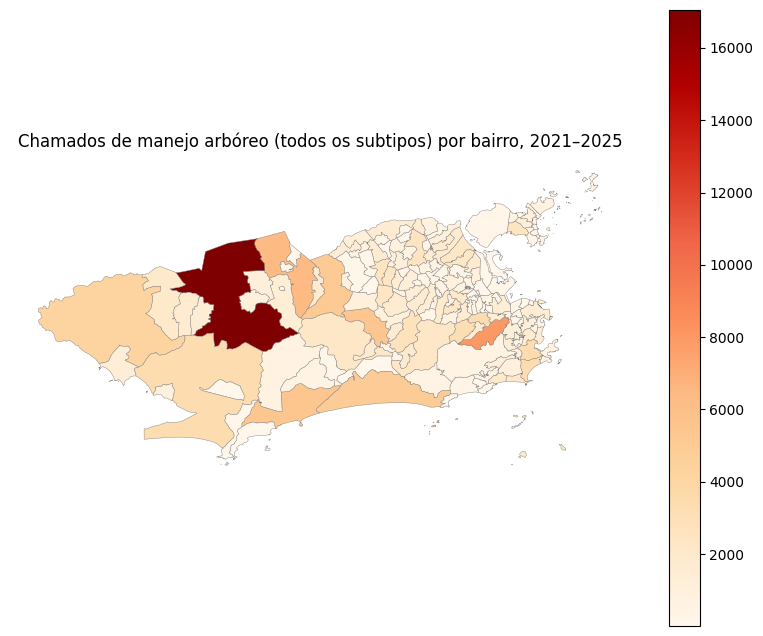

In [ ]:
from datetime import datetime
import matplotlib.pyplot as plt

P = [
    bigquery.ScalarQueryParameter("ini", "DATETIME", datetime(2021, 1, 1)),
    bigquery.ScalarQueryParameter("fim", "DATETIME", datetime(2026, 1, 1)),
]

sql_manejo_bairro = """
SELECT id_bairro, COUNT(*) AS n_chamados
FROM `datario.adm_central_atendimento_1746.chamado`
WHERE tipo = 'Manejo Arbóreo'
  AND data_inicio >= @ini AND data_inicio < @fim
GROUP BY id_bairro
"""
cont_m = rodar(sql_manejo_bairro, P)
cont_m["id_bairro"] = cont_m["id_bairro"].astype("string").str.strip()

# Conferência da partição: total = nulos + casados + não casados
total = int(cont_m["n_chamados"].sum())
nulos = int(cont_m.loc[cont_m["id_bairro"].isna(), "n_chamados"].sum())
cont_m = (cont_m.dropna(subset=["id_bairro"])
          .groupby("id_bairro", as_index=False)["n_chamados"].sum())

mapa_m = bairros.merge(cont_m, on="id_bairro", how="left")
casados = int(mapa_m["n_chamados"].sum())

print("total:", total, "(esperado: 212501)")
print("id_bairro nulo:", nulos)
print("casados com a tabela de bairros:", casados)
print("id_bairro preenchido mas não casado:", total - nulos - casados)
print("bairros sem chamado:", mapa_m["n_chamados"].isna().sum())

fig, ax = plt.subplots(figsize=(10, 8))
mapa_m.plot(column="n_chamados", cmap="OrRd", legend=True, edgecolor="grey",
            linewidth=0.3, missing_kwds={"color": "lightgrey"}, ax=ax)
ax.set_axis_off()
ax.set_title("Chamados de manejo arbóreo (todos os subtipos) por bairro, 2021–2025")
plt.show()

212.501 chamados de manejo arbóreo no período; 6.507 sem bairro e todos os demais casados com a
tabela de bairros. Só 2 bairros não têm chamado.

## 4. Chamados por logradouro

In [ ]:
from datetime import datetime

# ---- período (início inclusivo, fim exclusivo) ----
DATA_INI = datetime(2021, 1, 1)
DATA_FIM = datetime(2026, 1, 1)

P = [
    bigquery.ScalarQueryParameter("ini", "DATETIME", DATA_INI),
    bigquery.ScalarQueryParameter("fim", "DATETIME", DATA_FIM),
]

sql_manejo = """
SELECT id_chamado, id_bairro, id_logradouro, numero_logradouro,
       subtipo, data_inicio, id_unidade_organizacional, reclamacoes
FROM `datario.adm_central_atendimento_1746.chamado`
WHERE tipo = 'Manejo Arbóreo'
  AND id_logradouro IS NOT NULL AND TRIM(id_logradouro) NOT IN ('', '0')
  AND data_inicio >= @ini AND data_inicio < @fim
"""
manejo_df = rodar(sql_manejo, P)
print(manejo_df.shape)

# conferência: período realmente coberto e volume por ano
print(manejo_df["data_inicio"].min(), "->", manejo_df["data_inicio"].max())
print(manejo_df["data_inicio"].dt.year.value_counts().sort_index())

# contagem de chamados por logradouro
contagem_logradouro = (
    manejo_df.groupby("id_logradouro")
    .size()
    .reset_index(name="n_chamados")
    .sort_values("n_chamados", ascending=False)
)
print(contagem_logradouro.head(20).to_string())
print(f"\nlogradouros distintos: {len(contagem_logradouro):,}")

custo estimado: 2.238 GB
(205994, 8)
2021-01-01 08:23:25 -> 2025-12-31 23:39:37
data_inicio
2021    35616
2022    38238
2023    48151
2024    42201
2025    41788
Name: count, dtype: int64
      id_logradouro  n_chamados
6034          24331         568
11607         68627         455
13194         87049         454
4166          17152         391
13814         95471         385
12892         83048         371
8741          37762         351
11816         70854         350
1401         120469         292
8649          36954         291
8677          37127         290
11180         63933         287
12278         76174         284
8993          40808         281
11395         66381         279
12204         75226         269
12058         73577         268
13498         91330         266
249          103473         265
1658          12609         265

logradouros distintos: 14,089


In [ ]:
from datetime import datetime
P = [
    bigquery.ScalarQueryParameter("ini", "DATETIME", datetime(2021, 1, 1)),
    bigquery.ScalarQueryParameter("fim", "DATETIME", datetime(2026, 1, 1)),
]

sql_log = """
SELECT id_logradouro,
       COUNT(*) AS n_manejo,
       COUNTIF(subtipo IN ('Poda de árvore em logradouro',
                           'Poda de árvore em vias públicas',
                           'Árvore - Poda')) AS n_poda
FROM `datario.adm_central_atendimento_1746.chamado`
WHERE tipo = 'Manejo Arbóreo'
  AND data_inicio >= @ini AND data_inicio < @fim
  AND id_logradouro IS NOT NULL AND TRIM(id_logradouro) NOT IN ('', '0')
GROUP BY id_logradouro
"""
log_m = rodar(sql_log, P).sort_values("n_manejo", ascending=False)

print(len(log_m), "logradouros | n_manejo:", int(log_m["n_manejo"].sum()),
      "| n_poda:", int(log_m["n_poda"].sum()))
print(log_m.head(20).to_string(index=False))

custo estimado: 1.625 GB
14089 logradouros | n_manejo: 205994 | n_poda: 131874
id_logradouro  n_manejo  n_poda
        24331       568     342
        68627       455     279
        87049       454     294
        17152       391     228
        95471       385     224
        83048       371     215
        37762       351     218
        70854       350     206
       120469       292     133
        36954       291     157
        37127       290     167
        63933       287     215
        76174       284     161
        40808       281     165
        66381       279     163
        75226       269     175
        73577       268     177
        91330       266     172
        12609       265     163
       103473       265     167


In [ ]:
poda_df = pd.read_parquet(ARQ_PODA)  # extração do notebook 03

In [ ]:
# 1) Os 1.841 sem logradouro são os mesmos sem bairro?
sem_log = poda_df["id_logradouro"].isna() | poda_df["id_logradouro"].astype(str).str.strip().isin(["", "0"])
sem_bai = poda_df["id_bairro"].isna()
print(pd.crosstab(sem_log, sem_bai, rownames=["sem logradouro"], colnames=["sem bairro"]))

# 2) Esparsidade por logradouro
print(log_m["n_poda"].describe())
print(log_m["n_poda"].value_counts().sort_index().head(10))
print("logradouros com n_poda == 0:", (log_m["n_poda"] == 0).sum())

# 3) Os 5 primeiros: via longa ou ID genérico?
top = ["24331", "68627", "87049", "17152", "95471"]
t = poda_df[poda_df["id_logradouro"].astype(str).str.strip().isin(top)]
print(t.groupby("id_logradouro")["numero_logradouro"].agg(["size", "nunique"]))
print(t.groupby("id_logradouro")["id_bairro"].nunique())

sem bairro       False  True 
sem logradouro               
False           131874      0
True                 0   1841
count      14089.0
mean      9.360068
std      16.327981
min            0.0
25%            1.0
50%            4.0
75%           10.0
max          342.0
Name: n_poda, dtype: Float64
n_poda
0     952
1    2932
2    1626
3    1194
4     858
5     766
6     635
7     538
8     403
9     382
Name: count, dtype: Int64
logradouros com n_poda == 0: 952
               size  nunique
id_logradouro               
17152           228      110
24331           342      200
68627           279      173
87049           294      181
95471           224      158
id_logradouro
17152     6
24331     7
68627     1
87049    28
95471     5
Name: id_bairro, dtype: int64


- Os 1.841 chamados sem logradouro são exatamente os mesmos sem bairro.
- A distribuição é muito esparsa: mediana de **4 podas por logradouro**, e 2.932 logradouros têm uma só.
- Os primeiros do ranking são vias longas (muitos números de porta distintos, vários bairros).

## 5. Nomes e extensão dos logradouros (`dados_mestres.logradouro`)

In [ ]:
for nome in ["logradouro", "numero_porta"]:
    t = client.get_table(f"datario.dados_mestres.{nome}")
    print(f"\n=== {nome} | {t.num_rows} linhas ===")
    for c in t.schema:
        print(f"  {c.name:35s} {c.field_type}")

# Amostra sem colunas de geometria (GEOGRAPHY) nem WKT
t = client.get_table("datario.dados_mestres.logradouro")
campos = [c.name for c in t.schema
          if c.field_type != "GEOGRAPHY" and "wkt" not in c.name.lower()]
amostra = client.list_rows(t, selected_fields=[s for s in t.schema if s.name in campos],
                           max_results=5).to_dataframe()
print(amostra.to_string(index=False))


=== logradouro | 132000 linhas ===
  id_trecho                           STRING
  id_logradouro                       STRING
  inicio_numero_porta_par             FLOAT
  final_numero_porta_par              FLOAT
  inicio_numero_porta_impar           FLOAT
  final_numero_porta_impar            FLOAT
  id_tipo_logradouro                  STRING
  tipo_logradouro_abreviado           STRING
  tipo_logradouro_extenso             STRING
  id_nobreza                          STRING
  nobreza                             STRING
  preposicao                          STRING
  nome_parcial                        STRING
  nome_completo                       STRING
  nome_mapa                           STRING
  id_bairro                           STRING
  nome_bairro                         STRING
  hierarquia                          STRING
  sentido_unico                       STRING
  velocidade_regulamentada            STRING
  tipo_trecho                         STRING
  data_ultima_edicao   

In [ ]:
sql_log_nome = """
SELECT id_logradouro,
       COUNT(*)                       AS n_trechos,
       COUNT(DISTINCT id_bairro)      AS n_bairros_cadastro,
       COUNT(DISTINCT nome_completo)  AS n_nomes,
       ANY_VALUE(nome_completo)       AS nome_completo
FROM `datario.dados_mestres.logradouro`
GROUP BY id_logradouro
"""
nomes = rodar(sql_log_nome)
nomes["id_logradouro"] = nomes["id_logradouro"].astype(str).str.strip()
print(len(nomes), "id_logradouro distintos | soma de trechos:", int(nomes["n_trechos"].sum()), "(esperado: 132000)")
print("ids com mais de um nome:", int((nomes["n_nomes"] > 1).sum()))

lm = log_m.copy()
lm["id_logradouro"] = lm["id_logradouro"].astype(str).str.strip()
lm = lm.merge(nomes, on="id_logradouro", how="left", indicator=True)   # LEFT a partir dos chamados
print(lm["_merge"].value_counts())
print("chamados de poda sem nome:", int(lm.loc[lm["_merge"] == "left_only", "n_poda"].sum()),
      "de", int(lm["n_poda"].sum()))
print(lm.head(20)[["id_logradouro", "nome_completo", "n_poda", "n_manejo",
                   "n_trechos", "n_bairros_cadastro"]].to_string(index=False))

custo estimado: 0.004 GB
44327 id_logradouro distintos | soma de trechos: 132000 (esperado: 132000)
ids com mais de um nome: 0
_merge
both          13913
left_only       176
right_only        0
Name: count, dtype: int64
chamados de poda sem nome: 466 de 131874
id_logradouro                         nome_completo  n_poda  n_manejo  n_trechos  n_bairros_cadastro
        24331              Estrada dos Bandeirantes     342       568        372                   8
        68627                   Rua Conde de Bonfim     279       455         69                   1
        87049                        Avenida Brasil     294       454       1108                  31
        17152               Avenida Cesário de Melo     228       391        284                   6
        95471                  Avenida das Américas     224       385        871                   3
        83048                           Rua Uruguai     215       371         27                   2
        37762                 Av

Os campeões em chamados são vias extensas, como a Estrada dos Bandeirantes (372 trechos, 8 bairros)
e a Avenida Brasil (1.108 trechos, 31 bairros). **Comparar logradouros exige normalizar pela extensão**
(chamados por trecho ou por km), ou trocar de unidade (trecho, CEP).

## 6. Mapa: bairros e os 10 logradouros com mais chamados

In [ ]:
from datetime import datetime
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
from shapely import wkt

# False = 2021–2025 (igual ao mapa de poda); True = todos os anos do catálogo (2026 é parcial)
TODOS_OS_ANOS = False
if TODOS_OS_ANOS:
    ini, fim, periodo = datetime(2000, 1, 1), datetime(2027, 1, 1), "todos os anos"
else:
    ini, fim, periodo = datetime(2021, 1, 1), datetime(2026, 1, 1), "2021–2025"

P = [
    bigquery.ScalarQueryParameter("ini", "DATETIME", ini),
    bigquery.ScalarQueryParameter("fim", "DATETIME", fim),
]

# 1) Manejo arbóreo por bairro (todos os subtipos)
sql_bairro_m = """
SELECT id_bairro, COUNT(*) AS n_chamados
FROM `datario.adm_central_atendimento_1746.chamado`
WHERE tipo = 'Manejo Arbóreo'
  AND data_inicio >= @ini AND data_inicio < @fim
GROUP BY id_bairro
"""
cont_m = rodar(sql_bairro_m, P)
cont_m["id_bairro"] = cont_m["id_bairro"].astype("string").str.strip()
total = int(cont_m["n_chamados"].sum())
nulos = int(cont_m.loc[cont_m["id_bairro"].isna(), "n_chamados"].sum())
cont_m = (cont_m.dropna(subset=["id_bairro"])
          .groupby("id_bairro", as_index=False)["n_chamados"].sum())
mapa_m = bairros.merge(cont_m, on="id_bairro", how="left")
casados = int(mapa_m["n_chamados"].sum())

print(f"[{periodo}] total: {total} | id_bairro nulo: {nulos} | casados: {casados} "
      f"| preenchido mas não casado: {total - nulos - casados}")
print("bairros sem chamado:", int(mapa_m["n_chamados"].isna().sum()))

# 2) Top 10 logradouros por chamados de manejo (desempate por id, para ser reprodutível)
sql_top = """
SELECT id_logradouro,
       COUNT(*) AS n_manejo,
       COUNTIF(subtipo IN ('Poda de árvore em logradouro',
                           'Poda de árvore em vias públicas',
                           'Árvore - Poda')) AS n_poda
FROM `datario.adm_central_atendimento_1746.chamado`
WHERE tipo = 'Manejo Arbóreo'
  AND data_inicio >= @ini AND data_inicio < @fim
  AND id_logradouro IS NOT NULL AND TRIM(id_logradouro) NOT IN ('', '0')
GROUP BY id_logradouro
ORDER BY n_manejo DESC, id_logradouro
LIMIT 10
"""
top = rodar(sql_top, P)
top["id_logradouro"] = top["id_logradouro"].astype(str).str.strip()

# 3) Geometria dos trechos desses 10 logradouros (uma linha por trecho)
Pg = [bigquery.ArrayQueryParameter("ids", "STRING", top["id_logradouro"].tolist())]
tr = rodar("""
SELECT id_logradouro, nome_completo, geometry_wkt
FROM `datario.dados_mestres.logradouro`
WHERE id_logradouro IN UNNEST(@ids)
""", Pg)
print(len(tr), "trechos | sem geometria:", int(tr["geometry_wkt"].isna().sum()))

tr = tr[tr["geometry_wkt"].fillna("").str.len() > 0].copy()
tr["geometry"] = tr["geometry_wkt"].apply(wkt.loads)
trechos = gpd.GeoDataFrame(tr.drop(columns="geometry_wkt"), geometry="geometry", crs="EPSG:4326")
print(trechos.total_bounds)   # hipótese: lon/lat; esperado ≈ [-43.8, -23.1, -43.1, -22.7]

ruas = (trechos.dissolve(by="id_logradouro", aggfunc={"nome_completo": "first"})
        .reset_index()
        .merge(top, on="id_logradouro", how="left")
        .sort_values("n_manejo", ascending=False)
        .reset_index(drop=True))
print(ruas[["id_logradouro", "nome_completo", "n_manejo", "n_poda"]].to_string(index=False))
print("soma dos 10:", int(top["n_manejo"].sum()))

custo estimado: 0.658 GB
[2021–2025] total: 212501 | id_bairro nulo: 6507 | casados: 205994 | preenchido mas não casado: 0
bairros sem chamado: 2
custo estimado: 1.625 GB
custo estimado: 0.066 GB
3149 trechos | sem geometria: 0
[-43.69461392 -23.02138376 -43.19757642 -22.81243103]
id_logradouro                     nome_completo  n_manejo  n_poda
        24331          Estrada dos Bandeirantes       568     342
        68627               Rua Conde de Bonfim       455     279
        87049                    Avenida Brasil       454     294
        17152           Avenida Cesário de Melo       391     228
        95471              Avenida das Américas       385     224
        83048                       Rua Uruguai       371     215
        37762             Avenida de Santa Cruz       351     218
        70854           Avenida Epitácio Pessoa       350     206
       120469 Avenida Prefeito Dulcídio Cardoso       292     133
        36954             Estrada do Rio Grande       291 

GeoDataFrame GeoDataFrame EPSG:4326 10
count          165.0
mean     1248.448485
std      1767.319858
min             10.0
25%            315.0
50%            749.0
75%           1553.0
max          17048.0
Name: n_chamados, dtype: Float64


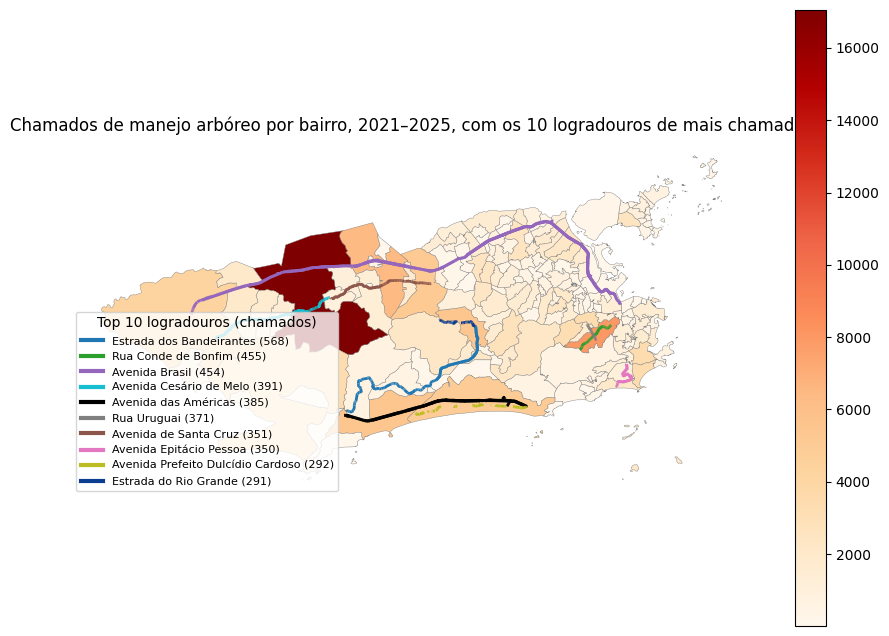

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Conferência: ambos devem ser GeoDataFrame, com CRS EPSG:4326
print(type(mapa_m).__name__, type(ruas).__name__, ruas.crs, len(ruas))
print(mapa_m["n_chamados"].describe())

cores = ["#1f77b4", "#2ca02c", "#9467bd", "#17becf", "#000000",
         "#7f7f7f", "#8c564b", "#e377c2", "#bcbd22", "#0b3d91"]

fig, ax = plt.subplots(figsize=(11, 8))
mapa_m.plot(column="n_chamados", cmap="OrRd", legend=True, edgecolor="grey",
            linewidth=0.3, missing_kwds={"color": "lightgrey"}, ax=ax)
handles = []
for i, cor in enumerate(cores[:len(ruas)]):
    ruas.iloc[[i]].plot(ax=ax, color=cor, linewidth=2)
    handles.append(Line2D([0], [0], color=cor, lw=3,
                          label=f"{ruas.loc[i, 'nome_completo']} ({int(ruas.loc[i, 'n_manejo'])})"))
ax.legend(handles=handles, title="Top 10 logradouros (chamados)", loc="lower left", fontsize=8)
ax.set_axis_off()
ax.set_title("Chamados de manejo arbóreo por bairro, 2021–2025, com os 10 logradouros de mais chamados")

fig.savefig(FIG_DIR / "mapa_manejo_top10.png", dpi=150, bbox_inches="tight")
plt.show()

---

⬅️ [03 · Qualidade dos dados e extração base](03_qualidade_e_extracao.ipynb) &nbsp;|&nbsp; [🏠 Início](README.md) &nbsp;|&nbsp; [05 · Poda → queda: o chamado de poda antecipa a queda da árvore?](05_poda_queda.ipynb) ➡️